# Analysis of Rhythmic Activity in the Scalp EEG
## 1st part case study
### lecturer: Conrado A. Bosman

## Introduction
In this tutorial, we will study the foundations of Fourier decomposition and how to implement it in Python. The contents of this lecture are from *Kramer & Eden, "Case studies in neural data analysis"* and *Mike X. Cohen, "MATLAB for Neuroscientists*.

Set the `PAND_2025` environment in your Jupyter notebook.

## LFP recap
From my previous ACN lecture on *Local Field Potentials (LFP)*, we learnt that the LFP is the low-frequency (<~300 Hz) component of the extracellular voltage recorded by an electrode in brain tissue. Instead of reflecting the activity of a single neuron, the LFP captures the **summed transmembrane currents** from many nearby neurons (on the order of a few hundred micrometers around the electrode tip). It is dominated by synaptic currents and other slow membrane processes (e.g., dendritic integration), while the fast, high-frequency components are more closely related to action potentials. In other words, the LFP tells us about the **shared input and collective dynamics** of the local population.

Under linear volume conduction and quasistatic assumptions (Maxwell equations), the extracellular potential at position $(\mathbf{r})$ and time $(\mathbf{t})$ can be written as a superposition of the contributions from all current sources $(I_n(t))$ located at positions $(\mathbf{r}_n)$:

$$
\phi(\mathbf{r}, t) \;=\; \frac{1}{4\pi \sigma} \sum_{n=1}^{N} \frac{I_n(t)}{\lVert \mathbf{r} - \mathbf{r}_n \rVert}
$$

where $(\phi(\mathbf{r}, t))$ is the LFP, $(\sigma)$ is the (assumed homogeneous and isotropic) conductivity of the extracellular medium, and the sum runs over all transmembrane current sources in the local volume. In practice, our electrode measures $(\phi(\mathbf{r}, t))$ at a fixed $(\mathbf{r})$, giving us a single-channel LFP trace that reflects the **spatiotemporal average** of many microscopic currents.

## Case study: Rhythmic activity in scalp EEG

In this tutorial, we start with a clinical scenario:  

- A patient arrives unconscious at the hospital emergency room.  
- As part of the neurological work-up, a standard **scalp EEG** is recorded with **21 electrodes** for about **10 minutes** at **1000 Hz** (1000 samples per second).  
- From this recording, the clinician sends you a **2s segment** from one electrode for an initial quantitative assessment.

We will treat this 2s segment as our dataset and use it to explore how rhythmic activity appears in the **time** and **frequency** domains.

### Aim of this tutorial

Using a **2s segment of scalp EEG sampled at 1000 Hz**, our goal is to:

- **Visualize** the data and get an intuitive sense of the ongoing rhythms.
- **Quantify** rhythmic activity in the **time domain** (autocovariance).
- **Characterize** rhythmic activity in the **frequency domain** (power spectrum).
- **Identify and attenuate** line noise (60 Hz) using simple modeling.
- **Track dynamics over time** using a time–frequency decomposition (spectrogram).

To do this, we will use three main tools:

1. **Fourier transform** – to decompose the signal into sinusoids.
2. **Power spectral density (spectrum)** – to estimate the strength of rhythms at each frequency.
3. **Spectrogram (short-time Fourier transform)** – to visualize how the spectrum evolves over time.

The rest of the notebook will walk through these steps in Python, starting from loading the EEG segment and ending with a full time–frequency overview of its rhythmic content.

## Load the data and info

Let's start importing the packages that are necessary for the analysis of the data:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy import signal
from pathlib import Path

plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['font.size'] = 12

Use the following code to load and plot the raw data. Be sure that the file `Ch3-EEG-1.mat` (MATLAB file) is in the folder `chapter3_Data`. Place this folder in the same directory of this Jupyter notebook:

In [2]:
# Base directory = folder where this notebook lives
base_dir = Path().resolve()

data_file = base_dir / "chapter3_Data" / "Ch3-EEG-1.mat"

# Load EEG data from MATLAB file
mat = loadmat(data_file)

# Adjust these keys if your .mat file uses different names
t = mat["t"].squeeze()          # time vector (seconds)
EEG = mat["EEG"].squeeze()      # EEG signal in microvolts, shape (N,)

Please note that the data is not continuous, but sampled at 1000 samples per second. This creates three crucial variables:
$$
\begin{aligned}
\Delta = 1~ \text{ms} \\
N = \text{total points} \\
T = N\Delta \\
\end{aligned}
$$

In Python, we can represent these variables as:

In [3]:
x = EEG                         # short name, following the slides
dt = t[1] - t[0]                # sampling interval
Fs = 1.0 / dt                   # sampling frequency (Hz)
N = len(x)                      # number of samples
T = N * dt                      # total duration (seconds)

print(f"Sampling rate: {Fs:.1f} Hz")
print(f"Number of samples: {N}")
print(f"Total duration: {T:.3f} s")

Sampling rate: 1000.0 Hz
Number of samples: 2000
Total duration: 2.000 s


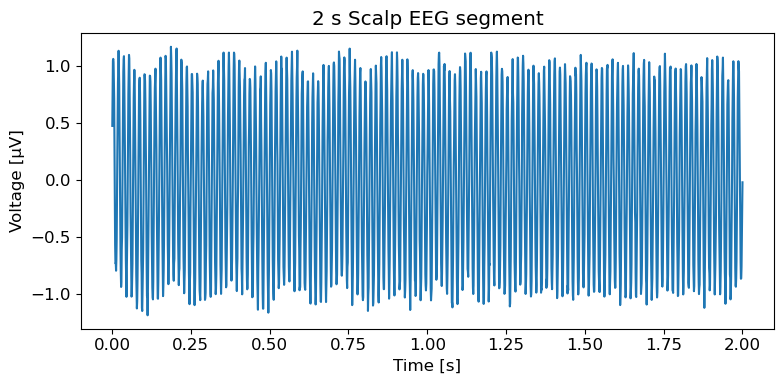

In [4]:
# Plot raw EEG

plt.figure()
plt.plot(t, x)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [µV]")
plt.title("2 s Scalp EEG segment")
plt.tight_layout()
plt.show()

## Basic analysis: mean and variance

We start by computing the mean, variance, and standard deviation of the EEG segment:

$$
\bar{x} = \frac{1}{N}\sum_{n=1}^N x_n,
\quad
\sigma^2 = \frac{1}{N}\sum_{n=1}^N (x_n - \bar{x})^2
$$

In [4]:
mn = np.mean(x)
vr = np.var(x)          # population variance (N in denominator)
sd = np.std(x)          # population std

print(f"Mean: {mn:.3f} µV")
print(f"Variance: {vr:.3f} µV²")
print(f"Standard deviation: {sd:.3f} µV")

Mean: 0.000 µV
Variance: 0.505 µV²
Standard deviation: 0.710 µV


## Rhythms in the Time Domain: Autocovariance (biased and unbiased)

In *ACN*, we learnt that a way to investigate the internal structure of a signal is by using the **autocovariance** of a signal. For a discrete-time signal $(x_n)$ with sampling interval $(\Delta t)$, the autocovariance at lag $(L)$ samples is defined as

$$
r_{xx}[L] = \frac{1}{N} \sum_{n=1}^{N-L} \bigl(x_{n+L} - \bar{x}\bigr)\bigl(x_n - \bar{x}\bigr),
$$

where $(\bar{x})$ is the sample mean and $(N)$ is the total number of data points. By evaluating $(r_{xx}[L])$ for different lags, we can reveal **rhythmic structure** in the data: oscillations appear as regularly spaced peaks in the autocovariance function.

![Autocovariance cartoon](chapter3_Data/autocov.png)

The figure above gives an intuitive picture of how the autocovariance is computed for different lags \(L\).

- The top row shows the original discrete signal $(x = [x_1, x_2, x_3, \dots, x_N])$.
- For **lag (L=0)**, we multiply the signal by itself **without any shift**.  
  Each sample $(x_n)$ is multiplied by $(x_n)$, and we sum all these products to obtain $(r_{xx}[0])$. This tells us how strong the signal is overall (its variance).
- For **lag (L=1)**, we shift a copy of the signal **one sample to the right**.  
  Now each $(x_n)$ is multiplied by $(x_{n+1})$: we are comparing each point with its **immediate neighbor in time**. Summing these products gives $(r_{xx}[1])$.
- For **lag (L = 2)**, we shift the copy by **two samples**, and multiply $(x_n)$ with $(x_{n+2})$, summing the overlapping products to obtain $(r_{xx}[2])$.

In general, the autocovariance at lag $(L)$ measures how similar the signal is to a **shifted version of itself**. If the signal contains a rhythm with period $(P)$, then the products will line up particularly well around lags $(L \approx P, 2P, 3P,\dots)$, producing peaks in $(r_{xx}[L])$ at those lags.

To implement this analysis in Python, we first defined a **function** called `autocovariance` that computes this metric:

In [5]:
def autocovariance(x, max_lag, biased=True):
    """
    Compute autocovariance for lags -max_lag..+max_lag.
    x is 1D array, max_lag is number of samples.
    """
    x = x - np.mean(x)
    N = len(x)
    corr = signal.correlate(x, x, mode="full")  # length 2N-1
    lags = np.arange(-N + 1, N)
    
    # extract only desired lags
    idx = np.where((lags >= -max_lag) & (lags <= max_lag))[0]
    corr = corr[idx]
    lags = lags[idx]
    
    if biased:
        ac = corr / N
    else:
        ac = corr / (N - np.abs(lags))
    return ac, lags

Here, we compute and plot the autocovariance:

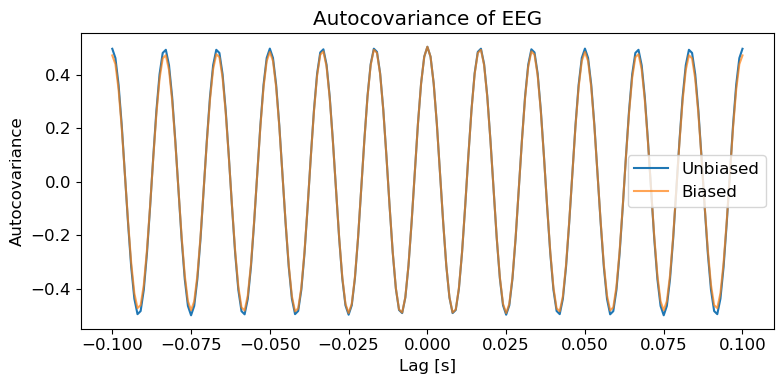

In [6]:
max_lag_s = 0.1                     # 100 ms window
max_lag_samples = int(max_lag_s * Fs)

ac_biased, lags = autocovariance(x, max_lag_samples, biased=True)
ac_unbiased, _ = autocovariance(x, max_lag_samples, biased=False)

lag_times = lags * dt

plt.figure()
plt.plot(lag_times, ac_unbiased, label="Unbiased")
plt.plot(lag_times, ac_biased, label="Biased", alpha=0.7)
plt.xlabel("Lag [s]")
plt.ylabel("Autocovariance")
plt.title("Autocovariance of EEG")
plt.legend()
plt.tight_layout()
plt.show()

Now, with a **time lag** of 2 seconds:

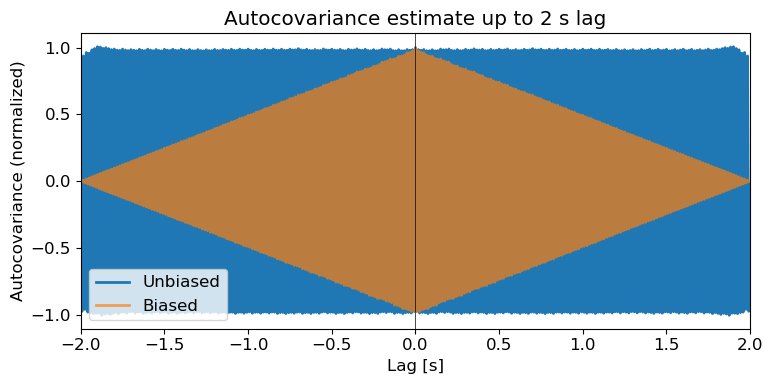

In [7]:
# Autocovariance up to 2 seconds, biased vs unbiased

max_lag_s = 2.0                            # 2 seconds
max_lag_samples = int(max_lag_s * Fs)

ac_biased, lags = autocovariance(x, max_lag_samples, biased=True)
ac_unbiased, _ = autocovariance(x, max_lag_samples, biased=False)

lag_times = lags * dt

# optional: normalize by r_xx[0] so they have comparable scale
ac0 = ac_unbiased[lags == 0][0]
ac_biased_norm   = ac_biased   / ac0
ac_unbiased_norm = ac_unbiased / ac0

plt.figure(figsize=(8, 4))
plt.plot(lag_times, ac_unbiased_norm, label="Unbiased", linewidth=2)
plt.plot(lag_times, ac_biased_norm,   label="Biased",   linewidth=2, alpha=0.7)
plt.axvline(0, color="k", linewidth=0.5)
plt.xlim(-2, 2)
plt.xlabel("Lag [s]")
plt.ylabel("Autocovariance (normalized)")
plt.title("Autocovariance estimate up to 2 s lag")
plt.legend()
plt.tight_layout()
plt.show()

### Why do we obtain this figure?

When we estimate the autocovariance from a finite data segment, we can use two
different normalizations:

- **Biased estimator** (divide by $N$):

$$
\hat r_{xx}^{(b)}[L]
= \frac{1}{N} \sum_{n=1}^{N-L} (x_{n+L}-\bar{x})(x_n-\bar{x})
$$

- **Unbiased estimator** (divide by $N-L$):

$$
\hat r_{xx}^{(u)}[L]
= \frac{1}{N-L} \sum_{n=1}^{N-L} (x_{n+L}-\bar{x})(x_n-\bar{x})
$$

The difference is in the denominator. For large lags $L$, there are fewer
overlapping pairs $(x_n, x_{n+L})$. The unbiased estimator corrects for this by
dividing by the actual number of pairs $N-L$, so that, on average,
$\mathbb{E}[\hat r_{xx}^{(u)}[L]] \approx r_{xx}[L]$. However, this comes at a cost:

- For large $|L|$, the unbiased estimator becomes very noisy, because it is
  based on only a few samples but scaled up by $N-L$.
- The biased estimator uses the same denominator $N$ for all lags, so the
  high-lag values are systematically pushed toward zero (negative bias), but
  the curve is smoother and better behaved.

In practice:

- If we care about an accurate estimate of $r_{xx}[L]$ at a few small lags,
  the **unbiased** estimator can be useful.
- If we want to use the autocovariance as input for **spectral analysis**
  (for example via the FFT), the **biased** estimator is often preferred because
  it leads to a stable, positive semi-definite covariance sequence and a smoother
  spectrum.

In the figure above (lags up to 2 s), you can see that both estimators are
similar around $L = 0$, but they diverge for large $|L|$: the unbiased
autocovariance shows large fluctuations, while the biased version is damped
towards zero

## Rhythms in the Frequency Domain: From Fourier transform to DFT and FFT

Conceptually, Fourier analysis starts from an **ideal, continuous-time** world:

- We imagine a signal $x(t)$ that exists for all real times $t$.
- Its frequency content is described by the **continuous-time Fourier transform** (FT):

$$
X(f) = \int_{-\infty}^{\infty} x(t)\, e^{-i 2\pi f t}\, dt
$$

Here $f$ is a continuous frequency variable. This is a beautiful mathematical object, but not exactly what we have in the lab: we never observe $x(t)$ for all $t$, and we do not measure continuously in time.

---

### Sampling in time: discrete-time signal

In the real world, we record $x(t)$ at discrete time steps, for example every $\Delta t = 1\ \text{ms}$:

$$
x_n = x(n \Delta t), \quad n = 0, 1, 2, \dots
$$

This gives us a **discrete-time** signal $\{x_n\}$ but, in principle, it is still of infinite length (we could keep recording forever). Its exact frequency representation is the **discrete-time Fourier transform** (DTFT), which is a function of a *continuous* frequency variable but periodic in frequency. We almost never compute the DTFT directly in practice.

---

### Windowing in time: the discrete Fourier transform (DFT)

In experiments, we only work with a **finite segment** of data, for example $N$ samples corresponding to $T = N \Delta t$ seconds. If we take those $N$ samples

$$
x_0, x_1, \dots, x_{N-1}
$$

we can compute the **discrete Fourier transform (DFT)**:

$$
X_k = \sum_{n=0}^{N-1} x_n\, e^{-i 2\pi \frac{k n}{N}},
\quad k = 0, 1, \dots, N-1
$$

Now we have:

- A **finite-time** signal (length $N$).
- A **finite set of frequency bins** $f_k$ with spacing $\Delta f = 1/T$.

This is the object we actually use in numerical work. The **power spectrum** in our tutorial is computed directly from these DFT coefficients $X_k$.

---

### FFT: how we actually compute the DFT

Mathematically, the DFT is just a sum. If we computed it naively, the cost would scale like $N^2$ (for each of $N$ frequencies we sum over $N$ time points). For signals with thousands or millions of samples, this would be far too slow.

The **fast Fourier transform (FFT)** is a family of clever algorithms (such as Cooley–Tukey) that compute exactly the same DFT, but in roughly

$$
\mathcal{O}(N \log N)
$$

operations instead of $\mathcal{O}(N^2)$. This is why we can so easily compute spectra and spectrograms on modern data.

In this notebook we will not implement the FFT ourselves. Instead, we use the highly optimized implementation provided by NumPy:

- `np.fft.fft(x)` computes the complex DFT $X_k$ for all frequencies.
- `np.fft.rfft(x)` does the same but takes advantage of real-valued data, returning only the non-negative frequencies.

So the conceptual hierarchy is:

- **Fourier transform (FT)**: continuous time, continuous frequency.
- **DTFT**: discrete time, continuous and periodic frequency.
- **DFT**: finite-time, discrete set of frequencies (what we compute).
- **FFT**: efficient algorithm to compute the DFT (what NumPy calls under the hood).

In Python, a Fourier analysis of the *2 seconds EEG signal* of the unconscious patient can be calculated as it follows: 

Frequency resolution df = 0.500 Hz
Nyquist frequency f_NQ = 500.0 Hz


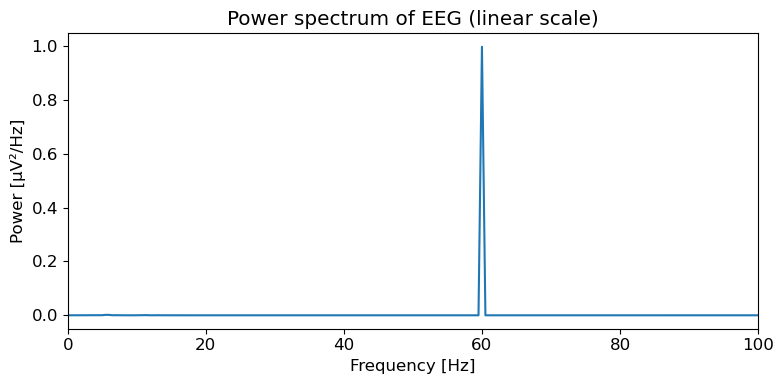

In [8]:
# Demean
x_demean = x - mn

# FFT (one-sided)
xf = np.fft.rfft(x_demean)
faxis = np.fft.rfftfreq(N, d=dt)  # frequency axis

# Power spectral density with scaling:
Sxx = 2 * (dt**2) / T * (xf * np.conj(xf)).real

df = 1.0 / T
fNQ = Fs / 2.0

print(f"Frequency resolution df = {df:.3f} Hz")
print(f"Nyquist frequency f_NQ = {fNQ:.1f} Hz")

# Plotting the figure:
plt.figure()
plt.plot(faxis, Sxx)
plt.xlim(0, 100)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [µV²/Hz]")
plt.title("Power spectrum of EEG (linear scale)")
plt.tight_layout()
plt.show()

## Intermezzo: Conceptual Foundations of Fourier Analysis

The code above calculates the **power spectrum** of an EEG signal using Fourier Analysis. As you can see, several concepts require further explanation to fully understand how Fourier analysis operates. Let's take a brief moment to discuss some **core concepts** of how to calculate the Fourier spectrum of a signal. Check the PDF of the slides of this Tutorial/Lecture. The code displayed in the PDF is transcribed below.

### A "real" sinewave

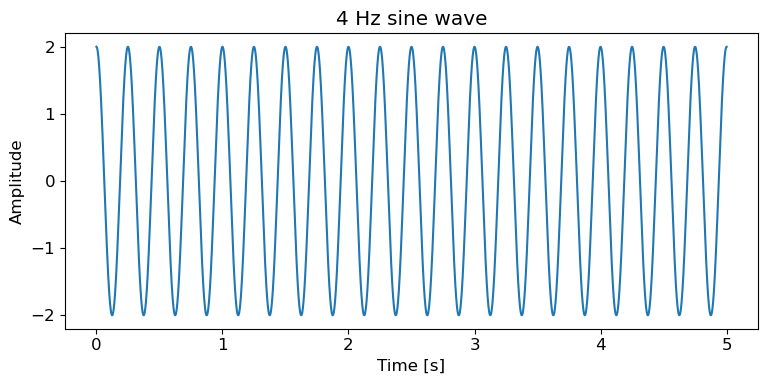

In [11]:
# Parameters
srate = 1000          # sampling rate in Hz
dt = 1 / srate        # sampling interval
f = 4                 # frequency in Hz
a = 2                 # amplitude (arbitrary units)
th = np.pi / 2        # phase in radians

# Time vector: from 0 to 5 seconds, including both endpoints (like MATLAB 0:1/srate:5)
time = np.arange(0, 5 + dt, dt)

# Sine wave
sinewave = a * np.sin(2 * np.pi * f * time + th)

# Plot
plt.figure()
plt.plot(time, sinewave)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("4 Hz sine wave")
plt.tight_layout()
plt.show()

### Complex numbers in Python

In Python, complex numbers are built in—you don’t need any special library.

- A complex number has the form `a + bj`, where:
  - `a` is the **real** part
  - `b` is the **imaginary** part
  - `j` plays the role of the imaginary unit (instead of $i$)

#### Literal syntax

```python
z1 = 3 + 4j      # 3 + 4i
z2 = -1.5 - 2j
z3 = 0 + 1j      # purely imaginary
```

#### Using the complex() constructor

```python
z = complex(3,4) #3 + 4j
```

#### Accessing real part, imaginary part, and magnitude

```python
z = 3 + 4j

z.real    # 3.0
z.imag    # 4.0
abs(z)    # 5.0 (magnitude: sqrt(3^2 + 4^2))
```

#### Complex arrays with NumPy

```python
import numpy as np

z = np.array([1+2j, 3-4j])

z.real      # array([1., 3.])
z.imag      # array([ 2., -4.])
np.abs(z)   # magnitudes of each element
```

### A "Complex" Sinewave

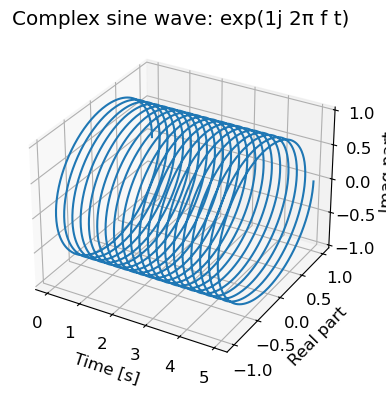

In [14]:
from mpl_toolkits.mplot3d import Axes3D  # needed to activate 3D plotting

# Parameters
srate = 1000            # sampling rate in Hz
dt = 1 / srate
f = 4                   # frequency in Hz

# Time vector: 0 to 5 seconds (inclusive, like MATLAB 0:1/srate:5)
time = np.arange(0, 5 + dt, dt)

# Complex sine wave (complex exponential)
csw = np.exp(1j * 2 * np.pi * f * time)

# 3D plot: time vs real vs imaginary parts
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.plot(time, csw.real, csw.imag)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Real part")
ax.set_zlabel("Imag part")
ax.set_title("Complex sine wave: exp(1j 2π f t)")

plt.tight_layout()
plt.show()

### Power spectrum as a function of FFT samples

When we compute the discrete Fourier transform (DFT) of our EEG segment, we get
a vector of complex numbers

$$
X_k, \quad k = 0, 1, \dots, N-1,
$$

where $N$ is the number of time samples in the EEG. At this point, the horizontal
axis is just the **index** $k$ (FFT sample number) — we have not yet turned this
into frequencies in Hz.

To go from Fourier coefficients to **power**, we normalize the **conjugate multiplication** of $X_k$ with the interval $\Delta t$ and total duration $T = N \Delta t$, we define:

$$
S_{xx}[k] = \frac{2\,\Delta t^2}{T}\, X_k X_k^*.
$$

We follow **Kramer & Eden’s** normalization because it gives a spectrum with sensible physical units ($\mu\mathrm{V}^2/\mathrm{Hz}$) and ensures that the total variance of the signal is equal to the area under the power spectrum. Other toolboxes use slightly different conventions, but they are all equivalent up to constant factors; the key is to be consistent within an analysis.\
This gives us a power value $S_{xx}[k]$ for each FFT index $k$. If we plot
$S_{xx}[k]$ as a function of $k$ for $k = 0, \dots, N-1$, we see that:

- The DFT gives us **$N$ power samples**, one for each index $k$.
- For our real-valued EEG signal, the power spectrum looks **symmetric**:
  the second half of the samples (the right side of the plot) is a **mirror**
  of the first half (the left side).

Intuitively:

- The **first half** of the indices (from the left up to the middle) already
  contains **all the meaningful information** about how power is distributed.
- The **second half** (from the middle to the right) is just a **duplicated
  mirror** of that information.

The code cell below will show this explicitly:

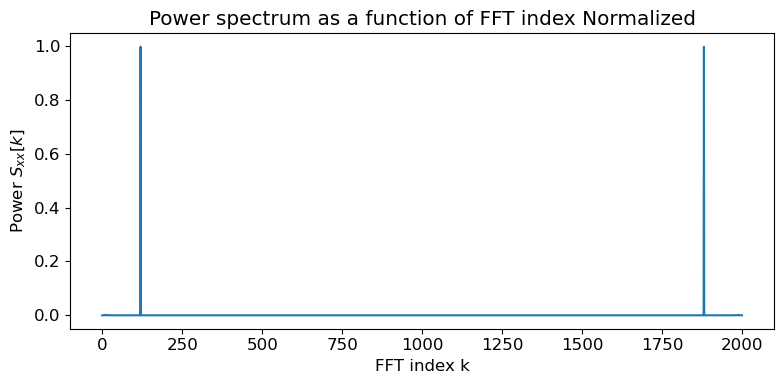

In [9]:
x_demean = x - np.mean(x)       # remove mean 
N = len(x_demean)               # N is total points

# Full FFT
X = np.fft.fft(x_demean)        # FFT
T = N*dt                        # total duration (seconds)

# Power Spectral Density  (normalized) as a function of FFT index k
Sxx = 2 * (dt**2) / T * (X * np.conj(X)).real               
k = np.arange(N)                # FFT indices

plt.figure(figsize=(8, 4))
plt.plot(k, Sxx)
plt.xlabel("FFT index k")
plt.ylabel("Power $S_{xx}[k]$")
plt.title("Power spectrum as a function of FFT index Normalized")
plt.tight_layout()
plt.show()

### From FFT samples to real frequencies: Nyquist and frequency resolution

So far we have treated the FFT output $S_{xx}[k]$ as a function of the **index**
$k = 0, 1, \dots, N-1$. Now we want to interpret these samples in terms of
**real frequencies in Hz**.

Our signal is:

- sampled at frequency $f_s$ (Hz),
- with sampling interval $\Delta t = 1 / f_s$,
- for a total duration $T$ seconds,
- giving $N = T f_s$ samples.

From these quantities, two key concepts follow.

---

#### Nyquist frequency

Because we only sample every $\Delta t$ seconds, we cannot distinguish
arbitrarily fast oscillations. The **highest meaningful frequency** in the
spectrum is the **Nyquist frequency**:

$$
f_{\text{NQ}} = \frac{f_s}{2}.
$$

This value sits exactly in the **middle** of the FFT:

- index $k = 0$ corresponds to **0 Hz** (DC),
- index $k = N/2$ (for even $N$) corresponds to **Nyquist** $f_{\text{NQ}}$,
- indices beyond $N/2$ are just the **mirror** of the lower half and do not
  add new information for a real-valued signal.

This explains why, in the previous plot, the spectrum looks **doubled**: the
FFT gives us $N$ samples, but only the first $N/2$ (from 0 to Nyquist) contain
unique information about the frequency content of the EEG.

An insufficient sampling frequency can distort signal analysis (Aliasing). Suppose you are interested in a particular frequency $f_s$ of your recording.

![Aliasing cartoon](chapter3_Data/Nyquist.png)

The figure shows the same continuous sine wave (black) sampled at three different rates.  
In the **top panel**, the sampling is fast (many green dots per cycle), so the discrete samples still follow the true waveform very closely. In the **middle panel**, we are close to the Nyquist limit (about two orange samples per cycle): the samples are just sufficient to reconstruct the original oscillation, but there is no “extra” detail. In the **bottom panel**, the sampling is too slow (few red dots per cycle), below the Nyquist frequency. Now the discrete samples trace out a much slower apparent oscillation that is not really present in the original signal—this is **aliasing**, where high-frequency content is misrepresented as a lower frequency because we sampled too slowly.

---

#### Frequency resolution

The second important quantity is how **finely** we can distinguish neighboring
frequencies. This is set by the total recording time $T$:

$$
\Delta f = \frac{1}{T}.
$$

This $\Delta f$ is the **frequency resolution**:

- The FFT does not give us a continuous frequency axis, but a grid:
  
  $$
  f_k = k \,\Delta f = \frac{k}{T}, \quad k = 0, 1, \dots, \frac{N}{2}.
  $$

- A longer recording ($T$ large) means **smaller** $\Delta f$ and therefore
  **finer** frequency resolution (more closely spaced frequency bins).
- A shorter recording ($T$ small) means **coarser** frequency resolution.

![Fresolution cartoon](chapter3_Data/resolution.png)

This figure illustrates the concept of **frequency resolution**. On the left, we see three signals with different numbers of samples: $N = 4$, $N = 8$, and $N = 16$. Suppose they are all sampled at the **same** sampling rate, so increasing $N$ means we recorded for a longer total time $T$. On the right, each case is mapped to the frequency axis from $0$ Hz to the Nyquist frequency $f_{\text{NQ}}$. As $N$ increases, the **spacing between frequency bins** $\Delta f$ becomes smaller, so more tick marks fit between 0 Hz and $f_{\text{NQ}}$. In other words, longer recordings (larger $N$ and $T$) give us **finer frequency resolution** $\Delta f = 1/T$, allowing us to distinguish closer frequencies in the spectrum.


Putting it together:

- The **Nyquist frequency** $f_{\text{NQ}} = f_s/2$ tells us **how far** the
  spectrum extends in Hz.
- The **frequency resolution** $\Delta f = 1/T$ tells us **how finely** the
  spectrum is sampled between 0 and $f_{\text{NQ}}$.

In the next code cells, we will construct the frequency axis using these
relationships and re-plot $S_{xx}[k]$ as a function of $f_k$ in Hz.


Frequency resolution df = 0.500 Hz
Nyquist frequency f_NQ = 500.0 Hz


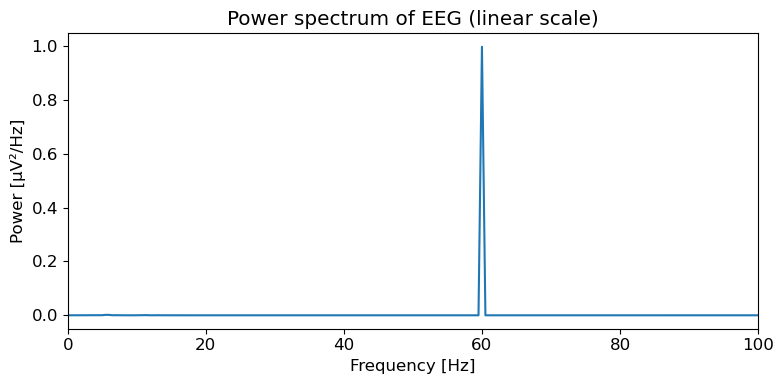

In [18]:
# FFT (one-sided)
xf = np.fft.rfft(x_demean)
faxis = np.fft.rfftfreq(N, d=dt)  # frequency axis

# Power spectral density with scaling:
Sxx = 2 * (dt**2) / T * (xf * np.conj(xf)).real

df = 1.0 / T       # frequency resolution
fNQ = Fs / 2.0     # Nyquist frequency

print(f"Frequency resolution df = {df:.3f} Hz")
print(f"Nyquist frequency f_NQ = {fNQ:.1f} Hz")

# Plotting the figure:
plt.figure()
plt.plot(faxis, Sxx)
plt.xlim(0, 100)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [µV²/Hz]")
plt.title("Power spectrum of EEG (linear scale)")
plt.tight_layout()
plt.show()

The 60 Hz peak dominates the spectrum, and lower-frequency activity may be hidden beneath it. To highlight these weaker contributions, we can **replot the power spectrum on a logarithmic (dB) scale**.

The code below normalizes the power spectrum by its **maximum value**, so the largest peak has value 1 (0 in dB scale). Logarithms compress the dynamic range, so smaller peaks that were hard to see on a linear scale become visible.

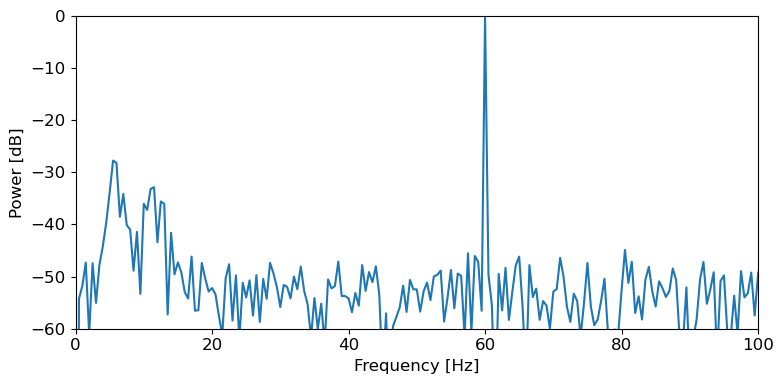

In [19]:
plt.figure()
plt.plot(faxis, 10 * np.log10(Sxx / np.max(Sxx)))   # power in dB
plt.xlim(0, 100)                                   # frequency range
plt.ylim(-60, 0)                                   # dB range
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.tight_layout()
plt.show()

The code below replots the power spectrum using a **logarithmic x-axis** and a
dB (logarithmic) y-axis. This stretches the low-frequency part of
the axis and compresses the high-frequency part. Using a log-frequency axis is helpful because:

- Low frequencies (e.g. 1–10 Hz) are spread out and more readable.
- Higher frequencies (e.g. 30–100 Hz) are compressed but still visible.
- Rhythms across a wide range of frequencies can be compared in a single, compact plot.

Together with the dB scale, this makes weaker low-frequency rhythms easier
to see, even when a strong peak (e.g. at 60 Hz) dominates the spectrum.:

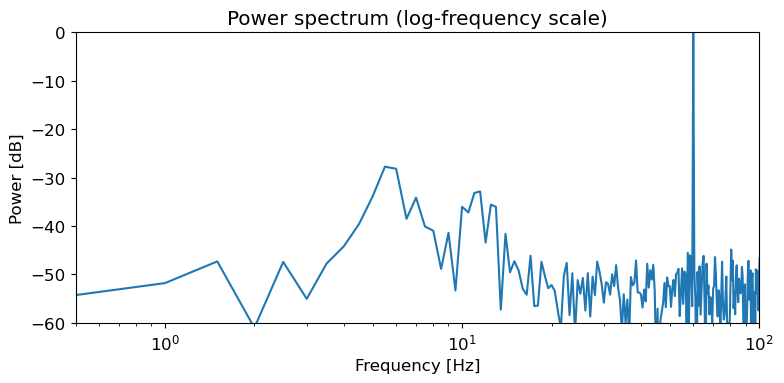

In [20]:
Sxx_norm = Sxx / np.max(Sxx)                # normalize by max
Sxx_db   = 10 * np.log10(Sxx_norm + 1e-20)  # power in dB, avoid log(0)

plt.figure()
plt.semilogx(faxis, Sxx_db)                 # log scale on x-axis
plt.xlim(df, 100)                           # from df to 100 Hz
plt.ylim(-60, 0)                            # dB range
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Power spectrum (log-frequency scale)")
plt.tight_layout()
plt.show()

In a clinical EEG, especially in an unconscious patient, the slow rhythms (delta and theta range) carry crucial information about brain state, prognosis, and possible pathology. Even if the recording is heavily contaminated by a strong 60 Hz line-noise peak, that high-frequency artifact does not destroy the underlying low-frequency structure of the signal. By looking at the spectrum on a dB / log-frequency scale (and later cleaning 60 Hz), we can still extract meaningful low-frequency activity that helps interpret the patient’s condition.

## Power, autocovariance, and the Wiener–Khinchin link

So far we have looked at **rhythmic activity** in two ways:

- In the **time domain**, via the **autocovariance** $r_{xx}[L]$.
- In the **frequency domain**, via the **power spectrum** $S_{xx}(f)$.

These are **not independent descriptions** of the signal. They are mathematically linked by the **Wiener–Khinchin theorem**:

$$
S_{xx}(f)
= \mathcal{F}\{r_{xx}[L]\}(f)
= \sum_{L=-\infty}^{\infty} r_{xx}[L]\, e^{-i 2\pi f L \Delta t}.
$$

In words:

- The **power spectrum** is the **Fourier transform of the autocovariance**.
- Equivalently, the autocovariance is the **inverse Fourier transform of the power spectrum**:

$$
r_{xx}[L]
= \int_{-\frac{1}{2\Delta t}}^{\frac{1}{2\Delta t}} S_{xx}(f)\, e^{i 2\pi f L \Delta t}\, df.
$$

---

### Intuition

You can think of it like this:

- The **autocovariance** $r_{xx}[L]$ measures **how similar the signal is to a shifted copy of itself** for each lag $L$.
  - If there is a strong rhythm at some period $P$, the signal will line up well with itself at lags $L \approx P, 2P, 3P,\dots$, producing **oscillations** in $r_{xx}[L]$.
- The **power spectrum** $S_{xx}(f)$ measures **how much variance (power) the signal has at each frequency** $f$.
  - A strong rhythm at frequency $f_0$ will appear as a **peak** in $S_{xx}(f)$ at $f_0$.

The Wiener–Khinchin theorem says that these two views are just **different projections of the same underlying structure**:

- Periodic structure in the **autocovariance** (oscillations as a function of lag) maps to **peaks in the spectrum** at the corresponding frequencies.
- Conversely, a sharp peak in the **spectrum** implies a long, slowly decaying oscillation in the **autocovariance**.

---

### Why this matters for our EEG example

For our 2 s EEG segment:

- When we see **oscillatory patterns** in the autocovariance $r_{xx}[L]$, we know there is a **preferred timescale** (or period) in the data.
- When we compute the power spectrum $S_{xx}(f)$, we are simply looking at the **same information**, but reorganized by **frequency** instead of **lag**.

This explains why:

- Cleaning a specific frequency band (for example, removing 60 Hz line noise) in the **spectrum** will change the corresponding **oscillatory component** in the autocovariance.
- Conversely, any systematic pattern we see in $r_{xx}[L]$ must show up somewhere in $S_{xx}(f)$.

In the rest of the notebook, when we compute the power spectrum using the FFT in NumPy, we are really using this **autocovariance–spectrum connection** in a fast and convenient way.


## Spectrogram: time–frequency representation

Sometimes we want to analyze **non-stationary signals**, where the frequency content changes over time. In that case, a single Fourier transform of the whole segment is not enough, because it loses all **time information**. A common solution is the **spectrogram**: we split the signal into short time windows and compute the Fourier transform **separately in each window**. To reduce boundary artifacts, these windows are usually **overlapped**, and the resulting procedure is known as the **short-time Fourier transform (STFT)**.


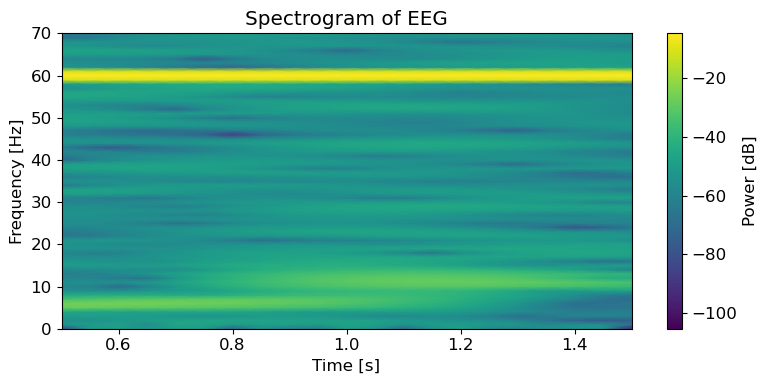

In [23]:
# Parameters:
interval = int(Fs)           # 1 s window
overlap = int(Fs * 0.95)     # 95% overlap
nfft = interval              # FFT length

f_spec, t_spec, Pxx = signal.spectrogram(
    x_demean,
    fs=Fs,
    window="hann",
    nperseg=interval,
    noverlap=overlap,
    nfft=nfft,
    scaling="density",
    mode="psd",
)

Pxx_db = 10 * np.log10(Pxx + 1e-20)

plt.figure(figsize=(8, 4))
plt.pcolormesh(t_spec, f_spec, Pxx_db, shading="gouraud")
plt.colorbar(label="Power [dB]")
plt.ylim(0, 70)
plt.xlabel("Time [s]")
plt.ylabel("Frequency [Hz]")
plt.title("Spectrogram of EEG")
plt.tight_layout()
plt.show()


## Summary

In this tutorial, we:

- Analyzed a **2 s segment of scalp EEG** from an unconscious patient using **spectral decomposition** techniques.
- Started with a **visual inspection** of the raw EEG, revealing a clear rhythmic pattern that is likely dominated by **line noise (60 Hz)** and other rhythmic activity.
- Computed the **autocovariance**, which showed a strong **oscillatory component in the time domain**, indicating preferred time scales in the signal.
- Applied the **discrete Fourier transform (via the FFT)** to obtain the **power spectrum**, allowing us to evaluate the same oscillatory component in the **frequency domain**.
- Discussed the **foundations of Fourier analysis**, including:
  - the distinction between the continuous Fourier transform and the discrete Fourier transform (DFT),
  - the role of the **FFT** as an efficient algorithm to compute the DFT.
- Introduced two key sampling-related concepts:
  - the **Nyquist frequency** $f_{\text{NQ}} = f_s/2$ as the highest meaningful frequency,
  - the **frequency resolution** $\Delta f = 1/T$ as the spacing between frequency bins.
- Used the **Kramer & Eden normalization** to obtain a power spectral density $S_{xx}(f)$ with interpretable units (e.g. $\mu\mathrm{V}^2/\mathrm{Hz}$) and a direct link between **variance in time** and **area under the spectrum**.
- Replotted the spectrum using **logarithmic (dB) scales** and a **log-frequency axis** to reveal **weaker low-frequency components** that are partly hidden under the dominant 60 Hz peak.
- Computed the **spectrogram (short-time Fourier transform)** to show how the spectral content **fluctuates across time**, which is crucial for analyzing **non-stationary** signals.
- Highlighted that, even in the presence of strong 60 Hz contamination, we can still extract **meaningful low-frequency activity**, which is clinically important for understanding the brain state of an unconscious patient.